# Predicting House Prices with Linear Regression

**Task:** DA5  
**Data provenance:** UCI Real Estate Valuation dataset; historical transactions in Sindian District, Taiwan.

This notebook calls a clearly separated, commented analysis module so the workflow can be run and maintained consistently. Run the cells from top to bottom. Metrics and plots are calculated at runtime; no results have been hand-entered. Synthetic-data outputs are demonstrations only.

## Notebook roadmap
This executed notebook separates data preparation, visualization, model training or analysis, and evaluation. Figures appear inline; each chart is followed by a written interpretation.

## Data Loading / EDA
Load the task dataset, verify its provenance and structure, and inspect its first descriptive summaries before visual or model analysis.

In [1]:
from pathlib import Path
import sys
project = Path.cwd().resolve()
if not (project / 'analysis_tasks.py').is_file():
    raise FileNotFoundError('Run Jupyter with this task folder as the working directory.')
sys.path.insert(0, str(project))
from analysis_tasks import *
from IPython.display import display
OUT_DIR.mkdir(exist_ok=True)
_chart_index = 0
_original_show = plt.show
def _save_inline_figure(*args, **kwargs):
    global _chart_index
    if plt.get_fignums():
        plt.gcf().savefig(OUT_DIR / f'notebook_chart_{_chart_index + 1:02d}.png', dpi=150, bbox_inches='tight')
        _chart_index += 1
    return _original_show(*args, **kwargs)
plt.show = _save_inline_figure


In [2]:
if not REAL_ESTATE_PATH.exists():
        raise FileNotFoundError(f"Download UCI Real Estate Valuation as described in README.md; expected {REAL_ESTATE_PATH}.")

print("DATA PROVENANCE: UCI Real Estate Valuation; historical Sindian District (Taiwan) transaction data.")

df=pd.read_excel(REAL_ESTATE_PATH,engine="openpyxl")

df=df.rename(columns={
        "X1 transaction date":"transaction_date",
        "X2 house age":"house_age_years",
        "X3 distance to the nearest MRT station":"distance_mrt_m",
        "X4 number of convenience stores":"convenience_stores",
        "X5 latitude":"latitude",
        "X6 longitude":"longitude",
        "Y house price of unit area":"price_per_ping_10k_twd",
    })

df=df.drop(columns=["No"],errors="ignore")

report(df)

print("Target unit: 10,000 New Taiwan dollars per ping; this historical dataset is not a current sale-price estimate.")

DATA PROVENANCE: UCI Real Estate Valuation; historical Sindian District (Taiwan) transaction data.
Shape: (414, 7)

Dtypes:
 transaction_date          float64
house_age_years           float64
distance_mrt_m            float64
convenience_stores          int64
latitude                  float64
longitude                 float64
price_per_ping_10k_twd    float64
dtype: object

Nulls:
 transaction_date          0
house_age_years           0
distance_mrt_m            0
convenience_stores        0
latitude                  0
longitude                 0
price_per_ping_10k_twd    0
dtype: int64

Descriptive statistics:
                         count         mean          std          min  \
transaction_date        414.0  2013.148953     0.281995  2012.666667   
house_age_years         414.0    17.712560    11.392485     0.000000   
distance_mrt_m          414.0  1083.885689  1262.109595    23.382840   
convenience_stores      414.0     4.094203     2.945562     0.000000   
latitude           

## Visualizations
Charts below are also saved as PNG files under `outputs/`. Read each finding before interpreting subsequent figures.

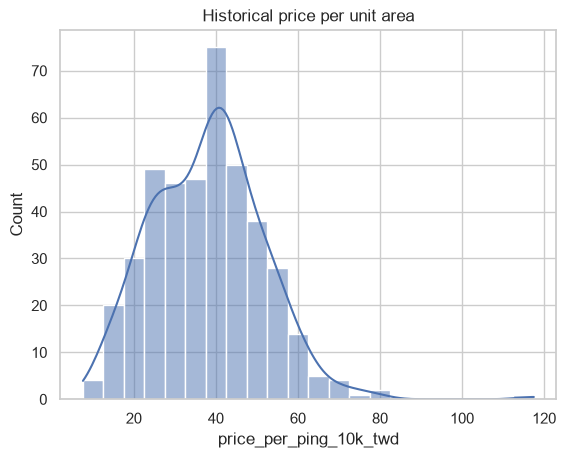

In [3]:
sns.histplot(df["price_per_ping_10k_twd"],kde=True)

plt.title("Historical price per unit area")

plt.show()

### Chart 1 interpretation
The target distribution reflects historical Sindian District transactions and the dataset?s price-per-ping unit; it is not a current local housing estimate.

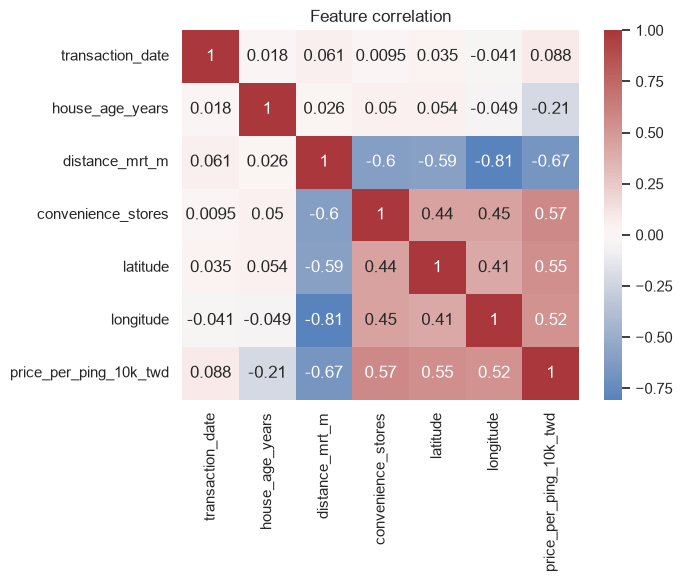

In [4]:
numeric=df.select_dtypes("number")

sns.heatmap(numeric.corr(),annot=True,cmap="vlag",center=0)

plt.title("Feature correlation")

plt.show()

### Chart 2 interpretation
Correlations can flag candidate predictors such as transit distance, but they are not causal effects and may be confounded by location.

In [5]:
print("Feature rationale: house age, proximity to transit, convenience-store count, and coordinates may relate to local price per unit area.")

df["location_zone"]=pd.cut(df["longitude"],bins=3,labels=["west","central","east"])

x=pd.get_dummies(df.drop(columns="price_per_ping_10k_twd"),columns=["location_zone"],drop_first=True,dtype=float)

y=df["price_per_ping_10k_twd"]

Feature rationale: house age, proximity to transit, convenience-store count, and coordinates may relate to local price per unit area.


## Model Training / Analysis
Fit and compare appropriate models, or perform the task-specific analytical transformation where supervised model training does not apply.

Linear Regression: MAE=4.537, RMSE=6.718, R²=0.731
Linear Regression MSE: 45.131116364054975
Ridge: MAE=5.177, RMSE=7.214, R²=0.690


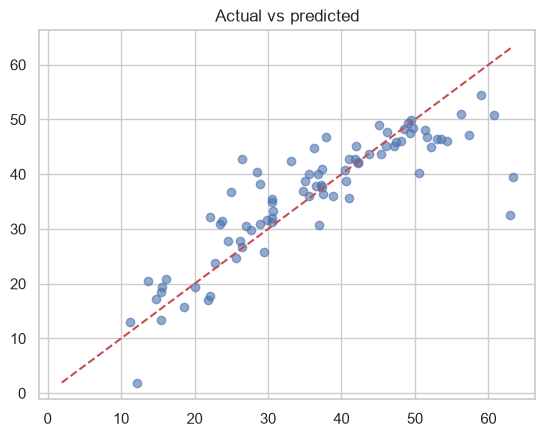

In [6]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=.2,random_state=SEED)

result=score_regressor("Linear Regression",LinearRegression(),x_train,x_test,y_train,y_test)

print("Linear Regression MSE:", result["rmse"] ** 2)

score_regressor("Ridge",__import__("sklearn.linear_model",fromlist=["Ridge"]).Ridge(alpha=1.0),x_train,x_test,y_train,y_test)

pred=result["prediction"]

plt.scatter(y_test,pred,alpha=.6)

lim=[min(y_test.min(),pred.min()),max(y_test.max(),pred.max())]

plt.plot(lim,lim,"r--")

plt.title("Actual vs predicted")

plt.show()

### Chart 3 interpretation
Actual-versus-predicted values near the diagonal indicate closer estimates. Large deviations show where the model misses expensive or unusual homes.

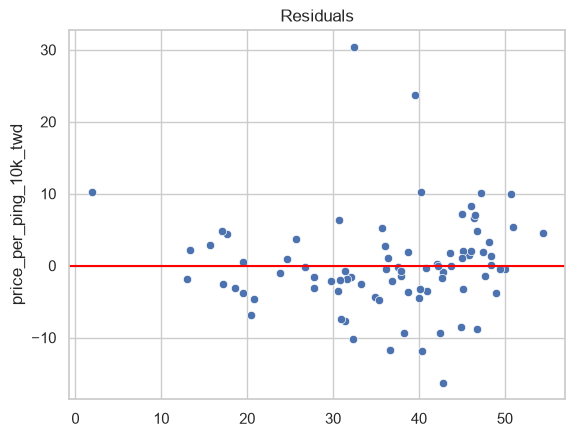

In [7]:
sns.scatterplot(x=pred,y=y_test-pred)

plt.axhline(0,color="red")

plt.title("Residuals")

plt.show()

### Chart 4 interpretation
Residuals centered around zero are desirable; trends or changing spread would signal systematic error and motivate a richer model.

In [8]:
print("Largest coefficients:\n",pd.Series(result["model"].coef_,index=x.columns).sort_values(key=abs,ascending=False).head(8))

Largest coefficients:
 latitude                 288.729276
longitude               -119.378413
location_zone_central    -11.041117
location_zone_east        -6.992852
transaction_date           5.575767
convenience_stores         0.606601
house_age_years           -0.292925
distance_mrt_m            -0.006837
dtype: float64


## Evaluation
Review the held-out metrics or descriptive analysis summary below. Predictive scores apply only to the documented dataset and split; non-predictive tasks report their analytical result and dataset coverage instead.

In [9]:
evaluation_rows = []
for variable in ('results', 'models', 'result'):
    candidate = globals().get(variable)
    candidates = candidate if isinstance(candidate, list) else [candidate]
    for row in candidates:
        if isinstance(row, dict):
            metrics = {key: value for key, value in row.items()
                       if isinstance(value, (int, float, np.number))
                       and not isinstance(value, (bool, np.bool_))}
            if metrics:
                evaluation_rows.append({'model': row.get('name', variable), **metrics})
if not evaluation_rows and {'y_test', 'pred'}.issubset(globals()):
    from sklearn.metrics import precision_score, recall_score, f1_score
    evaluation_rows.append({'model': 'Fraud holdout at threshold 0.50',
        'precision': precision_score(y_test, pred, zero_division=0),
        'recall': recall_score(y_test, pred, zero_division=0),
        'f1': f1_score(y_test, pred, zero_division=0)})
if evaluation_rows:
    evaluation = pd.DataFrame(evaluation_rows)
elif isinstance(globals().get('summary'), pd.DataFrame):
    evaluation = summary.copy()
elif isinstance(globals().get('profile'), pd.DataFrame):
    evaluation = profile.copy()
elif isinstance(globals().get('monthly'), pd.Series):
    evaluation = monthly.rename('revenue').to_frame()
else:
    evaluation = pd.DataFrame([{'analysis': 'Real Estate Price Regression',
        'rows': len(df) if isinstance(globals().get('df'), pd.DataFrame) else None,
        'columns': len(df.columns) if isinstance(globals().get('df'), pd.DataFrame) else None,
        'charts': _chart_index}])
display(evaluation)
evaluation_path = OUT_DIR / 'evaluation_summary.csv'
evaluation.to_csv(evaluation_path, index=True)
print(f'Saved {_chart_index} chart(s) and evaluation summary: {evaluation_path}')

,model,mae,rmse,r2
0,Linear Regression,4.536636,6.71797,0.730978


Saved 4 chart(s) and evaluation summary: D:\Oasis\DataAnalytics-L2-HousePriceRegression\outputs\evaluation_summary.csv
